In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## error-bar-plot

**Figure 1: GLUE accuracy of five fine-tuning methods, averaged over 5 seeds.** Points mark the mean and error bars show ±1 std over 5 seeds. Ours reaches 87.9%, 1.4 points above full fine-tuning (86.5%), about three times the spread over seeds (±0.5).

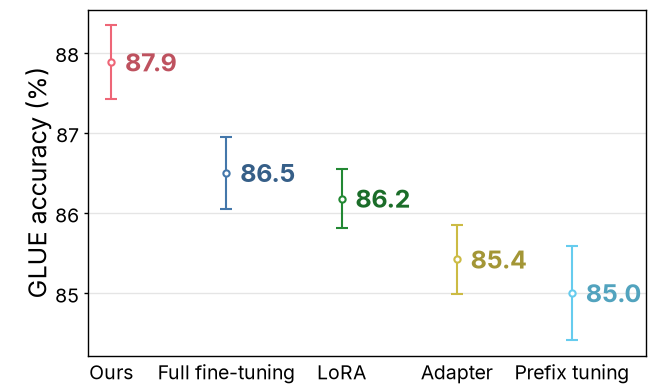

In [2]:
with open("../error-bar-plot.json") as f:
    accuracy_per_seed = json.load(f)["accuracy_per_seed"]

methods = ["Ours", "Full fine-tuning", "LoRA", "Adapter", "Prefix tuning"]
method_colors = [colors["ours"], colors["series-1"], colors["series-3"], colors["series-4"], colors["series-5"]]

fig, ax = plt.subplots(figsize=(3.25, 2), layout="constrained")
for x, (method, color) in enumerate(zip(methods, method_colors)):
    accuracy = 100 * np.array(accuracy_per_seed[method])
    mean, std = accuracy.mean(), accuracy.std(ddof=1)
    ax.errorbar(x, mean, yerr=std, fmt="o", color=color, capsize=2, elinewidth=0.75, capthick=0.75)
    ax.annotate(f"{mean:#.3g}", (x, mean), xytext=(5, 0), textcoords="offset points", va="center",
                fontweight="bold", color=darken(color))

ax.set_xticks(range(len(methods)), labels=methods)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("GLUE accuracy (%)")

fit_height(fig, ax, aspect=0.618)
fig.savefig("error-bar-plot.pdf")
fig.savefig("error-bar-plot.png")
plt.show()